# Dublin Fire Brigade Ambulance Response Times

What drives ambulance response times in Dublin, and can we predict which calls will receive a late response?

This notebook analyses 407,890 Dublin Fire Brigade ambulance calls from 2021 to 2025, using public data from Smart Dublin.

**Approach**
1. **Data cleaning and feature engineering:** combine five years of data, fix timing errors and build real-time demand features.
2. **Exploratory data analysis:** response times by hour of day and criticality level.
3. **Regression:** predict response time in minutes.
4. **Classification:** predict whether a response will be late for its criticality level.

Models are trained on 2021–2024 and tested on 2025, so they are always evaluated on future data they have not seen.

**Key results**
- The best classifier (logistic regression) flagged 86% of late responses, with an F1-macro of 0.63.
- The best regression model (random forest) predicted response times with a mean absolute error of 32.9 minutes (R² 0.27), compared with 34.8 minutes for the linear regression baseline.
- City-wide demand, meaning the number of incidents active across Dublin when a call comes in, was the strongest predictor of response time.


## Setup

In [ ]:
import pandas
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
import holidays 
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import RidgeCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import StackingRegressor
from sklearn.model_selection import StratifiedKFold, cross_val_score
from scipy.stats import bootstrap
from numpy import mean
from sklearn.model_selection import KFold
from sklearn.feature_selection import SelectKBest, mutual_info_regression
from sklearn.linear_model import LogisticRegression
from sklearn.inspection import permutation_importance
from sklearn.feature_selection import mutual_info_classif


## 1. Data cleaning and feature engineering

### Load the yearly files

In [149]:
data_2025 = pandas.DataFrame(pandas.read_csv("dfb-ambulance-incidents-2025.csv"))
data_2024 = pandas.DataFrame(pandas.read_csv("2024-dfb-ambulance-incidents-da.csv"))
data_2023 = pandas.DataFrame(pandas.read_csv("2023-open-data-dfb-ambulance.csv"))
data_2020_2022 = pandas.DataFrame(pandas.read_csv("da-opendata-2020-to-2022-with-stn-area.csv"))

### Combine into one dataset
The station column is named differently in some years, so it is standardised before the files are combined.

In [150]:
data_2025["Station Name"] = data_2025["Stat IDS with Stn Name DUB_Station Area"]
data_2024["Station Name"] = data_2024["Station Area"]

In [151]:
data = [data_2020_2022, data_2023, data_2024, data_2025]

df = pandas.concat(data, ignore_index=True)

In [152]:
df = df.drop(labels=["Station Area", "ID", "Stat IDS with Stn Name DUB_Station Area"], axis=1)

### Dates
Keep calls from 2021 onwards (407,890 calls) and extract the day, month and year.

In [153]:
df["Date"] = pandas.to_datetime(df["Date"], format="%d/%m/%Y")

df = df[df["Date"].dt.year >= 2021]

df["Day"] = df["Date"].dt.day
df["Month"] = df["Date"].dt.month
df["Year"] = df["Date"].dt.year

df

,Date,Station Name,criticality,TOC,ORD,MOB,IA,LS,AH,MAV,CD,Day,Month,Year
74258,2021-01-01,Tallaght Fire Station,D,00:03:21,01:04:19,01:08:22,NaN,NaN,NaN,NaN,NaN,1,1,2021
74259,2021-01-01,Swords Fire Station,D,00:08:39,00:13:09,00:14:59,00:18:33,00:56:00,01:09:52,00:59:31,NaN,1,1,2021
74260,2021-01-01,Tara Street Fire Station,C,00:16:26,00:21:56,00:25:41,00:33:03,NaN,NaN,00:59:00,NaN,1,1,2021
74261,2021-01-01,Swords Fire Station,B,00:17:48,03:23:20,03:27:27,NaN,NaN,NaN,03:47:38,NaN,1,1,2021
74262,2021-01-01,Tallaght Fire Station,B,00:25:43,00:31:05,00:34:33,00:55:52,01:13:05,01:19:09,01:53:58,NaN,1,1,2021
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
482143,2025-12-31,Dolphins Barn Fire Station,D,23:34:49,00:07:29,00:07:44,00:23:32,00:37:53,00:42:37,01:08:22,01:11:26,31,12,2025
482144,2025-12-31,Dolphins Barn Fire Station,C,23:35:27,00:33:16,00:33:56,00:52:01,00:52:01,00:56:02,01:08:33,01:14:16,31,12,2025
482145,2025-12-31,Kilbarrack Fire Station,C,23:35:58,03:02:01,03:05:24,NaN,NaN,NaN,03:12:19,03:19:36,31,12,2025
482146,2025-12-31,Dolphins Barn Fire Station,D,23:43:24,00:23:15,00:24:45,00:45:03,NaN,NaN,01:21:22,01:22:10,31,12,2025


### Remove invalid dispatch times
Times are recorded without dates, so negative gaps that cross midnight are shifted by 24 hours. Calls that took more than 6 hours to dispatch are treated as recording errors and removed.

In [114]:
dispatch = (pandas.to_timedelta(df["ORD"]) - pandas.to_timedelta(df["TOC"])).dt.total_seconds() / 60
dispatch = dispatch.where(dispatch >= 0, dispatch + 1440)
df = df[~(dispatch > 360)].copy()

### Real-time demand features
For every call, count how many incidents were active at that moment across the whole city (`Active City`) and within the same station area (`Active Area`).

In [115]:
df["call_dt"] = df["Date"] + pandas.to_timedelta(df["TOC"])

end = pandas.to_timedelta(df["CD"]).fillna(pandas.to_timedelta(df["MAV"]))

duration = end - pandas.to_timedelta(df["TOC"])
duration = duration.where(duration >= pandas.Timedelta(0), duration + pandas.Timedelta(days=1))

duration = duration.clip(upper=pandas.Timedelta(hours=6))

df["end_dt"] = df["call_dt"] + duration


def get_active(dataframe):
    known = dataframe.dropna(subset=["end_dt"])
    starts = np.sort(known["call_dt"].values)
    ends = np.sort(known["end_dt"].values)

    t = dataframe["call_dt"].values
    active = np.searchsorted(starts, t, side="left") - np.searchsorted(ends, t, side="right")
    return pandas.Series(active, index=dataframe.index)

df["Active City"] = get_active(df)

df["Active Area"] = df.groupby("Station Name", group_keys=False).apply(get_active)

### Response time
Drop calls with no arrival time rather than inventing outcomes, then calculate the minutes from call to arrival, correcting for calls that cross midnight.

In [116]:
df = df.dropna(subset=["IA"])

In [117]:
response = (pandas.to_timedelta(df["TOC"]) - pandas.to_timedelta(df["IA"])).dt.total_seconds()/60

response = response.where(response <= 0, response - 1440)

df["Response Time (minutes)"] = abs(response)

### Hour of call

In [118]:
df["Hour"] = df["TOC"].astype(str).str[:2]

### Check for outliers
The longest response times are inspected to find their cause.

Text(0.5, 0, 'All Responces')

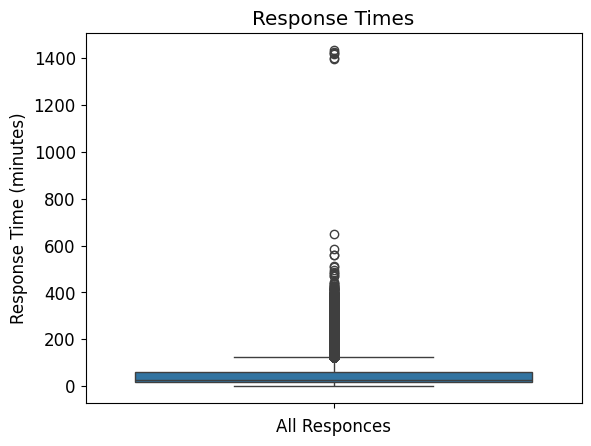

In [119]:
sns.boxplot(data=df["Response Time (minutes)"])
plt.title("Response Times")
plt.xlabel("All Responces")

In [120]:
df.sort_values(by="Response Time (minutes)", ascending=False)[:10]

,Date,Station Name,criticality,TOC,ORD,MOB,IA,LS,AH,MAV,CD,Day,Month,Year,call_dt,end_dt,Active City,Active Area,Response Time (minutes),Hour
383720,2024-10-27,Tara Street Fire Station,B,01:23:02,01:58:44,01:59:15,01:18:29,NaN,NaN,01:32:33,01:33:35,27,10,2024,2024-10-27 01:23:02,2024-10-27 01:33:35,20,5,1435.450000,01
221887,2022-10-30,North Strand Fire Station,C,01:39:54,01:58:17,01:59:16,01:26:31,01:52:17,01:58:15,02:24:11,NaN,30,10,2022,2022-10-30 01:39:54,2022-10-30 02:24:11,22,0,1426.616667,01
139966,2021-10-31,Balbriggan Fire Station,C,01:35:42,01:44:16,01:44:49,01:18:12,NaN,NaN,01:43:04,NaN,31,10,2021,2021-10-31 01:35:42,2021-10-31 01:43:04,18,0,1422.500000,01
221881,2022-10-30,Tallaght Fire Station,B,01:27:58,01:46:10,01:46:27,01:07:12,01:09:55,01:11:47,01:36:45,NaN,30,10,2022,2022-10-30 01:27:58,2022-10-30 01:36:45,19,6,1419.233333,01
139977,2021-10-31,Tara Street Fire Station,D,01:52:53,01:57:27,01:01:02,01:12:17,01:22:31,01:28:07,02:02:43,NaN,31,10,2021,2021-10-31 01:52:53,2021-10-31 02:02:43,19,6,1399.400000,01
302739,2023-10-29,Tara Street Fire Station,A,01:51:07,01:57:33,01:58:25,01:07:29,01:16:49,01:21:10,01:49:00,01:49:37,29,10,2023,2023-10-29 01:51:07,2023-10-29 07:51:07,17,5,1396.366667,01
227377,2022-11-23,Skerries Fire Station,C,10:15:34,13:19:30,13:20:21,21:04:42,21:23:27,21:38:56,NaN,NaN,23,11,2022,2022-11-23 10:15:34,NaT,20,0,649.133333,10
477323,2025-12-12,North Strand Fire Station,A,12:30:43,14:17:11,14:18:05,22:13:49,22:20:39,22:58:35,23:06:58,23:07:33,12,12,2025,2025-12-12 12:30:43,2025-12-12 18:30:43,20,2,583.100000,12
233965,2022-12-21,Dolphins Barn Fire Station,A,16:20:32,20:05:41,20:05:53,01:41:19,02:00:29,02:07:48,03:04:35,NaN,21,12,2022,2022-12-21 16:20:32,2022-12-21 22:20:32,21,0,560.783333,16
340119,2024-04-11,Kilbarrack Fire Station,D,21:45:33,22:03:02,22:04:50,07:03:17,07:26:45,08:18:44,08:32:54,08:41:00,11,4,2024,2024-04-11 21:45:33,2024-04-12 03:45:33,25,4,557.733333,21


### Daylight saving corrections
The longest response times traced back to the clock changes. Calls during the repeated hour when the clocks go back are removed, and calls that span the clocks going forward have an hour subtracted.

In [121]:
clocks_back = (
    (df["Date"].dt.month == 10)
    & (df["Date"].dt.dayofweek == 6)
    & (df["Day"] >= 25)
)


df = df[~(clocks_back & (pandas.to_timedelta(df["TOC"]) < pandas.Timedelta(hours=2)))]


In [122]:
clocks_forward = (
    (df["Date"].dt.month == 3)
    & (df["Date"].dt.dayofweek == 6)
    & (df["Day"] >= 25)
)

df.loc[clocks_forward & (pandas.to_timedelta(df["TOC"]) < pandas.Timedelta(hours=2)) & 
       (pandas.to_timedelta(df["IA"])  >= pandas.Timedelta(hours=2)) & (df["Response Time (minutes)"] > 60), "Response Time (minutes)"] -= 60


### Calendar features
Add public holidays, day of week and month name, and label missing criticality levels as Unknown. The cleaned data is also saved to `preproccesed.csv`.

In [ ]:
irish_holidays = holidays.Ireland(years=range(2020, 2026))

df["Holiday"] = df["Date"].dt.date.map(irish_holidays.get).fillna("None")
df["is_holiday"] = (df["Holiday"] != "None").astype(int)

df["Day of Week"] = df["Date"].dt.day_name()
df["Month Name"] = df["Date"].dt.month_name()

df["criticality"] = df["criticality"].replace("Null", "Unknown")

df = df.drop(labels=["Holiday"], axis=1)

df.to_csv("preproccesed.csv")

### Response times after cleaning

Text(0.5, 0, 'All Responces')

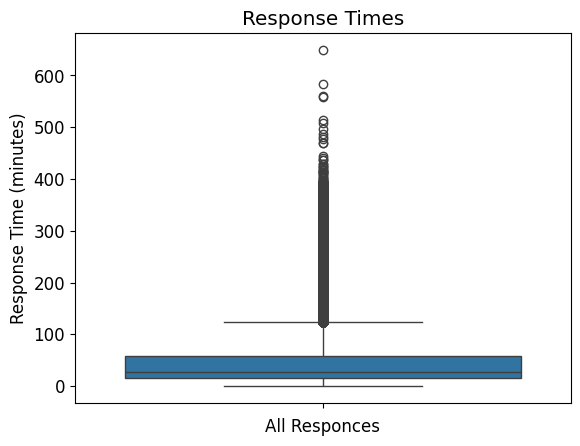

In [124]:
sns.boxplot(data=df["Response Time (minutes)"])
plt.title("Response Times")
plt.xlabel("All Responces")

## 2. Exploratory data analysis

### Response times and call volume by hour of day

In [125]:
median_response_time_hour = df.groupby(by=["Hour"])["Response Time (minutes)"].median()
mean_responses_hour = df.groupby(by=["Hour"])["Response Time (minutes)"].count()/len(df["Date"].unique())

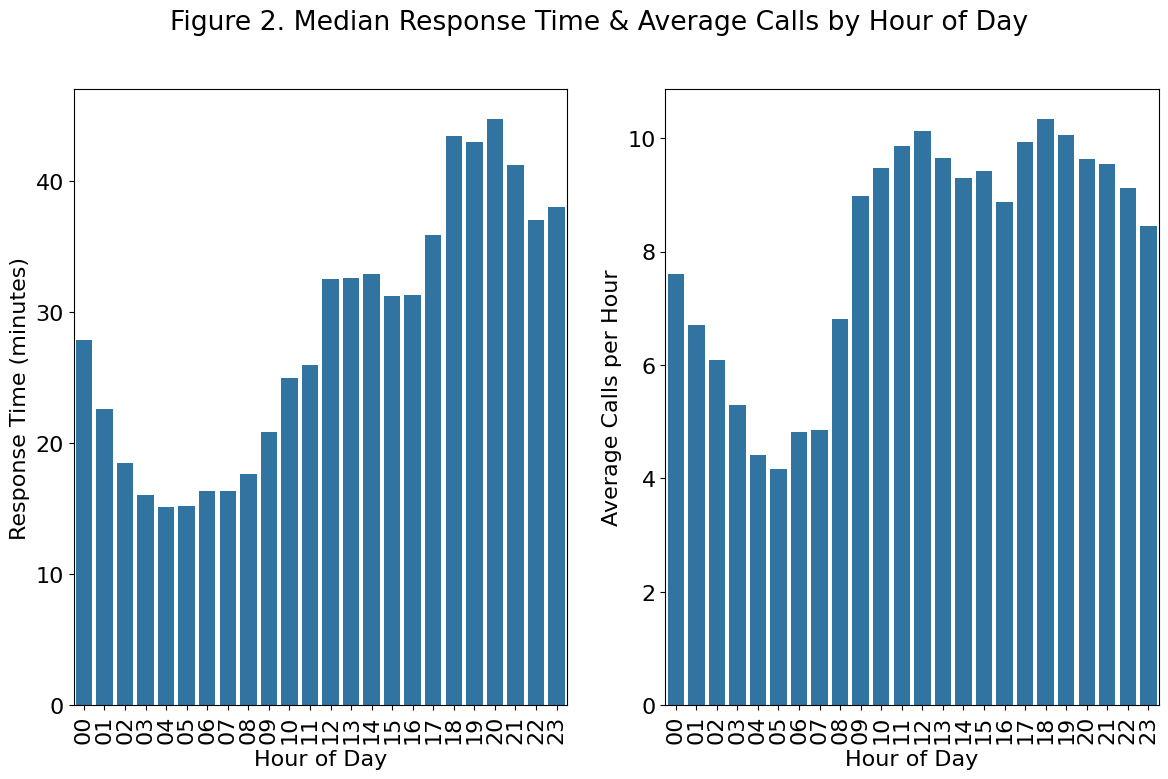

In [132]:
plt.rcParams.update({"font.size": 16})

fig, axs = plt.subplots(1, 2, figsize=(14,8))

sns.barplot(x=median_response_time_hour.index, y=median_response_time_hour.values, ax=axs[0])
axs[0].set_xlabel("Hour of Day")
axs[0].set_ylabel("Response Time (minutes)")
axs[0].tick_params(axis='x', labelrotation=90)

sns.barplot(x=mean_responses_hour.index, y=mean_responses_hour.values, ax=axs[1])
axs[1].set_xlabel("Hour of Day")
axs[1].set_ylabel("Average Calls per Hour")
axs[1].tick_params(axis='x', labelrotation=90)

plt.suptitle("Figure 2. Median Response Time & Average Calls by Hour of Day")
plt.show()

### Response times by criticality level

Text(0.5, 1.0, 'Figure 1. Response Times by Criticality Level (No Outliers)')

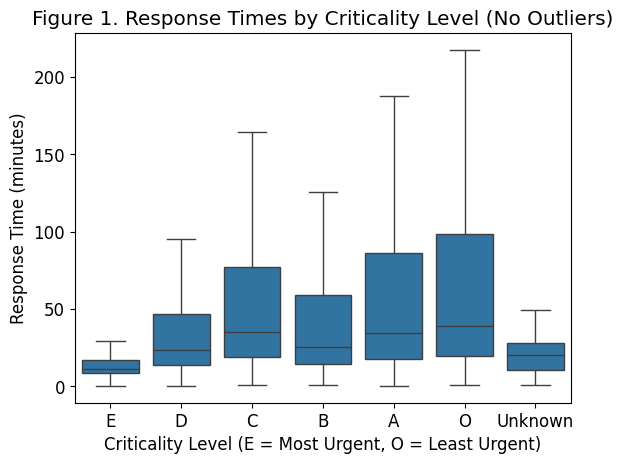

In [127]:
plt.rcParams.update({"font.size": 12})

order = ["E", "D", "C", "B", "A", "O", "Unknown"]

sns.boxplot(data=df, x="criticality", y="Response Time (minutes)", order=order, showfliers=False)
plt.xlabel("Criticality Level (E = Most Urgent, O = Least Urgent)")
plt.title("Figure 1. Response Times by Criticality Level (No Outliers)")

### Cleaned dataset

In [21]:
df

,Date,Station Name,criticality,TOC,ORD,MOB,IA,LS,AH,MAV,...,Year,call_dt,end_dt,Active City,Active Area,Response Time (minutes),Hour,is_holiday,Day of Week,Month Name
74259,2021-01-01,Swords Fire Station,D,00:08:39,00:13:09,00:14:59,00:18:33,00:56:00,01:09:52,00:59:31,...,2021,2021-01-01 00:08:39,2021-01-01 00:59:31,0,0,9.900000,00,1,Friday,January
74260,2021-01-01,Tara Street Fire Station,C,00:16:26,00:21:56,00:25:41,00:33:03,NaN,NaN,00:59:00,...,2021,2021-01-01 00:16:26,2021-01-01 00:59:00,1,0,16.616667,00,1,Friday,January
74262,2021-01-01,Tallaght Fire Station,B,00:25:43,00:31:05,00:34:33,00:55:52,01:13:05,01:19:09,01:53:58,...,2021,2021-01-01 00:25:43,2021-01-01 01:53:58,3,0,30.150000,00,1,Friday,January
74263,2021-01-01,Finglas Fire Station,D,00:26:50,01:10:25,01:11:06,01:15:49,01:28:36,01:34:58,01:56:33,...,2021,2021-01-01 00:26:50,2021-01-01 01:56:33,4,0,48.983333,00,1,Friday,January
74264,2021-01-01,Dolphins Barn Fire Station,D,00:44:10,02:17:02,02:18:29,02:24:40,02:36:23,02:39:46,02:59:26,...,2021,2021-01-01 00:44:10,2021-01-01 02:59:26,5,0,100.500000,00,1,Friday,January
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
482141,2025-12-31,Tallaght Fire Station,D,23:28:58,23:40:36,23:42:11,00:01:49,00:01:50,00:13:06,00:32:42,...,2025,2025-12-31 23:28:58,2026-01-01 00:33:09,28,3,32.850000,23,0,Wednesday,December
482143,2025-12-31,Dolphins Barn Fire Station,D,23:34:49,00:07:29,00:07:44,00:23:32,00:37:53,00:42:37,01:08:22,...,2025,2025-12-31 23:34:49,2026-01-01 01:11:26,26,1,48.716667,23,0,Wednesday,December
482144,2025-12-31,Dolphins Barn Fire Station,C,23:35:27,00:33:16,00:33:56,00:52:01,00:52:01,00:56:02,01:08:33,...,2025,2025-12-31 23:35:27,2026-01-01 01:14:16,27,2,76.566667,23,0,Wednesday,December
482146,2025-12-31,Dolphins Barn Fire Station,D,23:43:24,00:23:15,00:24:45,00:45:03,NaN,NaN,01:21:22,...,2025,2025-12-31 23:43:24,2026-01-01 01:22:10,28,3,61.650000,23,0,Wednesday,December


## 3. Regression: predicting response time in minutes

### Features and time-based split
Train on 2021–2024 and test on 2025.

In [ ]:
X = df.drop(labels=["Date", "TOC", "ORD", "MOB", "IA", "LS", "AH", "MAV", "CD", "Response Time (minutes)", "Day", "Month", "Year", "call_dt", "end_dt"], axis=1)
y = df["Response Time (minutes)"]

train = df["Date"].dt.year <= 2024

X_train , X_test = X[train], X[~train]
y_train_reg, y_test_reg = y[train], y[~train]
y_reg = y

### Preprocessing pipeline
Categorical features are one-hot encoded and the demand counts are scaled with a robust scaler. Preprocessing sits inside each model's pipeline, so it is fitted on training data only and no information leaks from the test set.

In [23]:
num_cols = ["Active City", "Active Area"]
cat_cols = X.drop(labels=num_cols, axis=1).columns

preprocess = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("num", RobustScaler(), num_cols)
])

### Linear regression (baseline)

In [24]:
lr_pipeline = Pipeline([
    ("process", preprocess),
    ("reg", LinearRegression())
])

In [25]:
lr_pipeline.fit(X_train, y_train_reg)

y_pred = lr_pipeline.predict(X_test)

In [ ]:
print(f"Test MAE: {mean_absolute_error(y_test_reg, y_pred)}")
print(f"Test RMSE: {root_mean_squared_error(y_test_reg, y_pred)}")
print(f"Test R²: {lr_pipeline.score(X_test, y_test_reg)}")

Test MAE: 34.8426704279209
Test RMSE: 49.71501946899905
Test R²: 0.238093639458123


### Decision tree, tuned with grid search

In [ ]:
param_grid = {
    "max_depth": [5, 10, 15, 20, 25],
    "min_samples_leaf": [20, 50, 100, 150]
}

search = GridSearchCV(
    Pipeline([("process", preprocess), ("reg", DecisionTreeRegressor(random_state=23364203))]),
    param_grid={"reg__max_depth": [5, 10, 15, 20, 25], "reg__min_samples_leaf": [20, 50, 100]},
    scoring="neg_mean_absolute_error", cv=5, n_jobs=-1)


search.fit(X_train, y_train_reg)

best_dt_params_reg = search.best_params_

best_dt_params_reg


{'reg__max_depth': 15, 'reg__min_samples_leaf': 100}

In [28]:
dt_reg_pipeline = search.best_estimator_


In [29]:
dt_reg_pipeline.fit(X_train, y_train_reg)

y_pred = dt_reg_pipeline.predict(X_test)

print(f"Test MAE: {mean_absolute_error(y_test_reg, y_pred)}")
print(f"Test RMSE: {root_mean_squared_error(y_test_reg, y_pred)}")
print(f"Test R²: {dt_reg_pipeline.score(X_test, y_test_reg)}")

Test MAE: 33.10252576978066
Test RMSE: 49.07757467519835
Test R²: 0.25750667007451733


### Ridge regression

In [ ]:
r_pipeline = Pipeline([
    ("process", preprocess),
    ("reg", RidgeCV(alphas=np.logspace(-3,3,13)))
])


In [31]:
r_pipeline.fit(X_train, y_train_reg)

y_pred = r_pipeline.predict(X_test)

print(f"Test MAE: {mean_absolute_error(y_test_reg, y_pred)}")
print(f"Test RMSE: {root_mean_squared_error(y_test_reg, y_pred)}")
print(f"Test R²: {r_pipeline.score(X_test, y_test_reg)}")

print("Best Alpha: ", r_pipeline.named_steps["reg"].alpha_)

Test MAE: 34.8406805118372
Test RMSE: 49.715026159023445
Test R²: 0.23809343440248654
Best Alpha:  31.622776601683793


### Ensembles: random forest and stacking

In [ ]:
rf_reg_pipeline = Pipeline([
    ("process", preprocess),
    ("reg", RandomForestRegressor(random_state=23364203, 
                                  max_depth=best_dt_params_reg["reg__max_depth"],
                                    min_samples_leaf=best_dt_params_reg["reg__min_samples_leaf"], 
                                    n_jobs=-1))
])

In [33]:
rf_reg_pipeline.fit(X_train, y_train_reg)

y_pred = rf_reg_pipeline.predict(X_test)

print(f"Test MAE: {mean_absolute_error(y_test_reg, y_pred)}")
print(f"Test RMSE: {root_mean_squared_error(y_test_reg, y_pred)}")
print(f"Test R²: {rf_reg_pipeline.score(X_test, y_test_reg)}")

Test MAE: 32.93632036169742
Test RMSE: 48.70977342689612
Test R²: 0.2685938791955441


In [ ]:
models = [
    ("lt", lr_pipeline),
    ("dt", dt_reg_pipeline),
   ("r",  r_pipeline)
]

stacking_reg = StackingRegressor(models, cv=5, n_jobs=-1)

In [35]:
stacking_reg.fit(X_train, y_train_reg)

y_pred = stacking_reg.predict(X_test)

print(f"Test MAE: {mean_absolute_error(y_test_reg, y_pred)}")
print(f"Test RMSE: {root_mean_squared_error(y_test_reg, y_pred)}")
print(f"Test R²: {stacking_reg.score(X_test, y_test_reg)}")

Test MAE: 33.25842734187765
Test RMSE: 48.735521386122045
Test R²: 0.2678204330881204


### Comparing models: bootstrap confidence intervals
Mean absolute error from 10-fold cross-validation on the training data, with 95% bootstrap confidence intervals.

In [ ]:
cv = KFold(n_splits=10)
scores = -cross_val_score(lr_pipeline, X_train, y_train_reg, cv=cv, n_jobs=-1,
                          scoring="neg_mean_absolute_error")
res_lr = bootstrap((scores,), mean, confidence_level=0.95, random_state=23364203)

In [51]:
cv = KFold(n_splits=10)
scores = -cross_val_score(dt_reg_pipeline, X_train, y_train_reg, cv=cv, n_jobs=-1,
                          scoring="neg_mean_absolute_error")
res_dt_reg = bootstrap((scores,), mean, confidence_level=0.95, random_state=23364203)

In [52]:
cv = KFold(n_splits=10)
scores = -cross_val_score(r_pipeline, X_train, y_train_reg, cv=cv, n_jobs=-1,
                          scoring="neg_mean_absolute_error")
res_r = bootstrap((scores,), mean, confidence_level=0.95, random_state=23364203)

In [53]:
cv = KFold(n_splits=10)
scores = -cross_val_score(stacking_reg, X_train, y_train_reg, cv=cv, n_jobs=-1,
                          scoring="neg_mean_absolute_error")
res_stacking_reg = bootstrap((scores,), mean, confidence_level=0.95, random_state=23364203)

In [54]:
cv = KFold(n_splits=10)
scores = -cross_val_score(rf_reg_pipeline, X_train, y_train_reg, cv=cv, n_jobs=-1,
                          scoring="neg_mean_absolute_error")
res_rf_reg = bootstrap((scores,), mean, confidence_level=0.95, random_state=23364203)

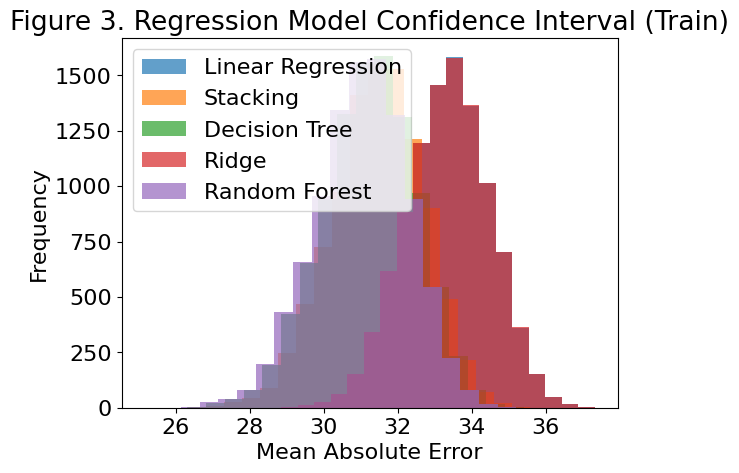

Linear Regression Confidence Interval: (30.828914492662253, 35.30697729591207)
Stacking Confidence Interval: (28.568655532014255, 33.484260971060316)
Decision Tree Confidence Interval: (28.197440516984063, 33.22696398594072)
Ridge Confidence Interval: (30.822226300776283, 35.30327715041961)
Random Forest Confidence Interval: (28.007589483184585, 33.02660590080019)


In [133]:
plt.hist(res_lr.bootstrap_distribution, bins=20, alpha=.7)
plt.hist(res_stacking_reg.bootstrap_distribution, bins=20, alpha=.7)
plt.hist(res_dt_reg.bootstrap_distribution, bins=20, alpha=.7)
plt.hist(res_r.bootstrap_distribution, bins=20, alpha=.7)
plt.hist(res_rf_reg.bootstrap_distribution, bins=20, alpha=.7)
plt.legend(["Linear Regression", "Stacking", "Decision Tree", "Ridge", "Random Forest"])
plt.ylabel("Frequency")
plt.xlabel("Mean Absolute Error")
plt.title("Figure 3. Regression Model Confidence Interval (Train)")
plt.show()

print(f"Linear Regression Confidence Interval: {float(res_lr.confidence_interval.low), float(res_lr.confidence_interval.high)}")
print(f"Stacking Confidence Interval: {float(res_stacking_reg.confidence_interval.low), float(res_stacking_reg.confidence_interval.high)}")
print(f"Decision Tree Confidence Interval: {float(res_dt_reg.confidence_interval.low), float(res_dt_reg.confidence_interval.high)}")
print(f"Ridge Confidence Interval: {float(res_r.confidence_interval.low), float(res_r.confidence_interval.high)}")
print(f"Random Forest Confidence Interval: {float(res_rf_reg.confidence_interval.low), float(res_rf_reg.confidence_interval.high)}")

### Feature selection and feature importance
Each model is refit using only the 5 most informative features. Permutation importance then shows how much the random forest's error increases when each feature is shuffled.

In [ ]:
lr_fs_pipeline = Pipeline([
    ("process", preprocess),
    ("select", SelectKBest(mutual_info_regression, k=5)),
    ("reg", LinearRegression())
])

In [78]:
lr_fs_pipeline.fit(X_train, y_train_reg)

y_pred = lr_fs_pipeline.predict(X_test)

print(f"Test MAE: {mean_absolute_error(y_test_reg, y_pred)}")
print(f"Test RMSE: {root_mean_squared_error(y_test_reg, y_pred)}")
print(f"Test R²: {lr_pipeline.score(X_test, y_test_reg)}")

Test MAE: 35.64350854741017
Test RMSE: 50.590765571325015
Test R²: 0.238093639458123


In [79]:
dt_reg_fs_pipeline = Pipeline([
    ("process", preprocess),
    ("select", SelectKBest(mutual_info_regression, k=5)),
    ("reg", DecisionTreeRegressor(random_state=23364203, 
                                  max_depth=best_dt_params_reg["reg__max_depth"],
                                    min_samples_leaf=best_dt_params_reg["reg__min_samples_leaf"] ))
])

In [80]:
dt_reg_fs_pipeline.fit(X_train, y_train_reg)

y_pred = dt_reg_fs_pipeline.predict(X_test)

print(f"Test MAE: {mean_absolute_error(y_test_reg, y_pred)}")
print(f"Test RMSE: {root_mean_squared_error(y_test_reg, y_pred)}")
print(f"Test R²: {dt_reg_pipeline.score(X_test, y_test_reg)}")

Test MAE: 33.81561484518387
Test RMSE: 49.569862826279405
Test R²: 0.25750667007451733


In [81]:
r_fs_pipeline = Pipeline([
    ("process", preprocess),
    ("select", SelectKBest(mutual_info_regression, k=5)),
    ("reg", RidgeCV(alphas=np.logspace(-3,3,13)))
])


In [82]:
r_fs_pipeline.fit(X_train, y_train_reg)

y_pred = r_fs_pipeline.predict(X_test)

print(f"Test MAE: {mean_absolute_error(y_test_reg, y_pred)}")
print(f"Test RMSE: {root_mean_squared_error(y_test_reg, y_pred)}")
print(f"Test R²: {r_pipeline.score(X_test, y_test_reg)}")

Test MAE: 35.64345038549307
Test RMSE: 50.59076810116886
Test R²: 0.23809343440248654


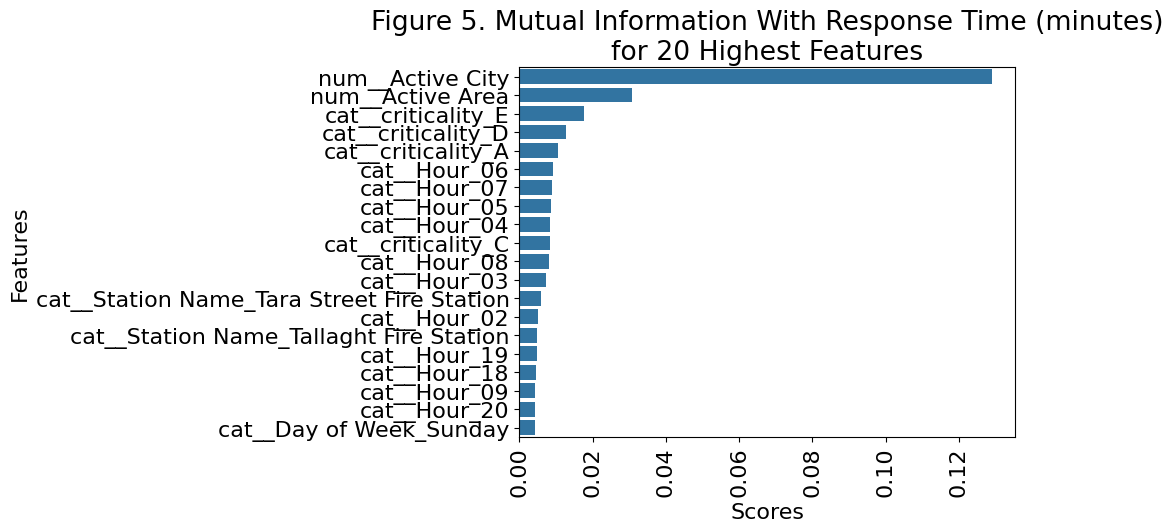

In [139]:
selector = r_fs_pipeline.named_steps["select"]
feature_names = r_fs_pipeline.named_steps["process"].get_feature_names_out()

feature_importance = pandas.DataFrame(selector.scores_, index=feature_names, columns=["Score"]).sort_values("Score", ascending=False)[:20]

sns.barplot(y=feature_importance.index, x=feature_importance["Score"])
plt.tick_params("x", rotation=90)
plt.ylabel("Features")
plt.xlabel("Scores")
plt.title("Figure 5. Mutual Information With Response Time (minutes)\nfor 20 Highest Features")
plt.show()

In [ ]:
result_rf_reg = permutation_importance(rf_reg_pipeline, X_test, y_test_reg,
                                scoring="neg_mean_absolute_error",
                                n_repeats=5, random_state=23364203, n_jobs=-1)
perm_rf_reg = pandas.Series(result_rf_reg.importances_mean, index=X_test.columns).sort_values(ascending=False)



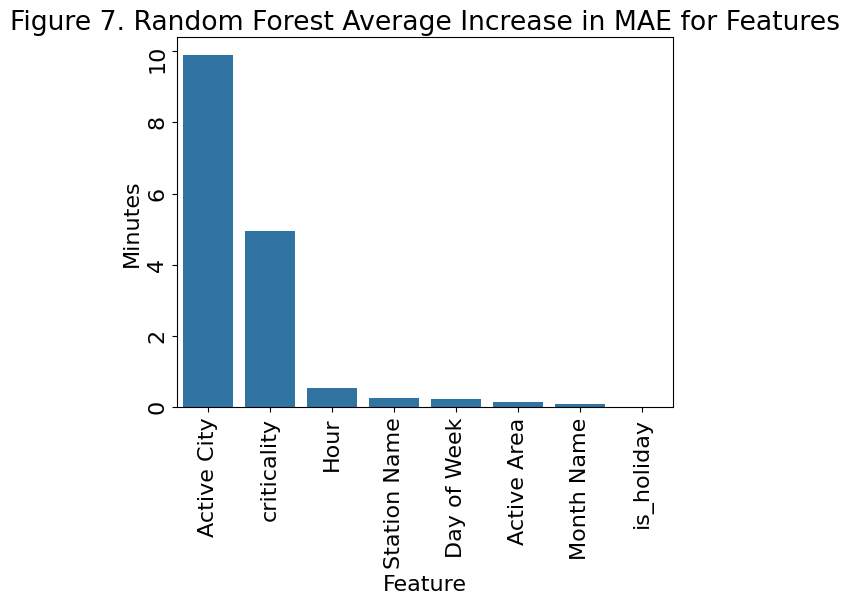

In [143]:
sns.barplot(perm_rf_reg)
plt.xlabel("Feature")
plt.ylabel("Minutes")
plt.tick_params(rotation=90)
plt.title("Figure 7. Random Forest Average Increase in MAE for Features")
plt.show()

## 4. Classification: predicting late responses

### Define a late response
A response counts as late if it is slower than 75% of training-set responses at the same criticality level, so each level is judged against its own standard rather than one fixed threshold.

In [36]:
thresholds = df[train].groupby("criticality")["Response Time (minutes)"].quantile(0.75)

df["late"] = (df["Response Time (minutes)"] > df["criticality"].map(thresholds)).astype(int)

In [37]:
y = df["late"]

y_train_clf, y_test_clf = y[train], y[~train]   

Text(0.5, 1.0, 'Late vs Not Late Responses Test Set')

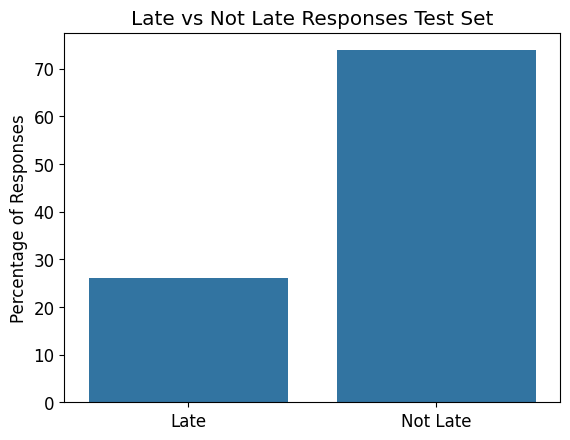

In [38]:
per_late = len(y_test_clf[y_test_clf.values == 1])/len(y_test_clf)*100
per_not_late = 100 - len(y_test_clf[y_test_clf.values == 1])/len(y_test_clf)*100




sns.barplot(x=["Late", "Not Late"], y=[per_late, per_not_late])
plt.ylabel("Percentage of Responses")
plt.title("Late vs Not Late Responses Test Set")

### Logistic regression
Class weights are balanced because late responses are the minority class.

In [ ]:
logr_pipeline = Pipeline([
    ("process", preprocess),
    ("clf", LogisticRegression(class_weight="balanced"))
])


In [40]:
from sklearn.metrics import f1_score, classification_report, confusion_matrix

logr_pipeline.fit(X_train, y_train_clf)

y_pred = logr_pipeline.predict(X_test)

print("F1 Macro: ", f1_score(y_test_clf, y_pred, average="macro"))
print("Classification Report:\n", classification_report(y_test_clf, y_pred))
print("Confusion Matrix\n", confusion_matrix(y_test_clf, y_pred))

F1 Macro:  0.6312618046212256
Classification Report:
               precision    recall  f1-score   support

           0       0.92      0.57      0.70     53483
           1       0.41      0.86      0.56     18901

    accuracy                           0.65     72384
   macro avg       0.67      0.72      0.63     72384
weighted avg       0.79      0.65      0.67     72384

Confusion Matrix
 [[30359 23124]
 [ 2565 16336]]


### Decision tree, tuned with grid search

In [41]:
from sklearn.tree import DecisionTreeClassifier


search = GridSearchCV(
    Pipeline([("process", preprocess), ("clf", DecisionTreeClassifier(random_state=23364203, class_weight="balanced"))]),
    param_grid={"clf__max_depth": [5, 10, 15, 20, 25, 30, 40, 50, 60], "clf__min_samples_leaf": [20, 50, 100]},
    scoring="f1_macro", cv=5, n_jobs=-1)


search.fit(X_train, y_train_clf)

best_dt_params_clf = search.best_params_

print(best_dt_params_clf)

{'clf__max_depth': 40, 'clf__min_samples_leaf': 50}


In [42]:
dt_clf_pipeline =  search.best_estimator_

In [43]:
dt_clf_pipeline.fit(X_train, y_train_clf)

y_pred = dt_clf_pipeline.predict(X_test)

print("F1 Macro: ", f1_score(y_test_clf, y_pred, average="macro"))
print("Classification Report:\n", classification_report(y_test_clf, y_pred))
print("Confusion Matrix\n", confusion_matrix(y_test_clf, y_pred))

F1 Macro:  0.6047588230440217
Classification Report:
               precision    recall  f1-score   support

           0       0.92      0.52      0.67     53483
           1       0.39      0.87      0.54     18901

    accuracy                           0.61     72384
   macro avg       0.66      0.70      0.60     72384
weighted avg       0.78      0.61      0.64     72384

Confusion Matrix
 [[28061 25422]
 [ 2451 16450]]


### K-nearest neighbours

In [44]:
from sklearn.neighbors import KNeighborsClassifier

knn_pipeline = Pipeline([
    ("process", preprocess),
    ("clf", KNeighborsClassifier(n_jobs=-1))
])

In [45]:
knn_pipeline.fit(X_train, y_train_clf)

y_pred = knn_pipeline.predict(X_test)

print("F1 Macro: ", f1_score(y_test_clf, y_pred, average="macro"))
print("Classification Report:\n", classification_report(y_test_clf, y_pred))
print("Confusion Matrix\n", confusion_matrix(y_test_clf, y_pred))

F1 Macro:  0.6027684323745326
Classification Report:
               precision    recall  f1-score   support

           0       0.79      0.85      0.82     53483
           1       0.45      0.35      0.39     18901

    accuracy                           0.72     72384
   macro avg       0.62      0.60      0.60     72384
weighted avg       0.70      0.72      0.70     72384

Confusion Matrix
 [[45379  8104]
 [12368  6533]]


### Ensembles: random forest and stacking

In [46]:
from sklearn.ensemble import RandomForestClassifier

rf_clf_pipeline = Pipeline([
    ("process", preprocess),
    ("clf", RandomForestClassifier(random_state=23364203, 
                                  max_depth=best_dt_params_clf["clf__max_depth"],
                                    min_samples_leaf=best_dt_params_clf["clf__min_samples_leaf"], 
                                    class_weight="balanced",
                                    n_jobs=-1))
])

In [47]:
rf_clf_pipeline.fit(X_train, y_train_clf)

y_pred = rf_clf_pipeline.predict(X_test)

print("F1 Macro: ", f1_score(y_test_clf, y_pred, average="macro"))
print("Classification Report:\n", classification_report(y_test_clf, y_pred))
print("Confusion Matrix\n", confusion_matrix(y_test_clf, y_pred))

F1 Macro:  0.6118190545506117
Classification Report:
               precision    recall  f1-score   support

           0       0.94      0.52      0.67     53483
           1       0.40      0.90      0.55     18901

    accuracy                           0.62     72384
   macro avg       0.67      0.71      0.61     72384
weighted avg       0.80      0.62      0.64     72384

Confusion Matrix
 [[27815 25668]
 [ 1813 17088]]


In [48]:
from sklearn.ensemble import StackingClassifier

models = [
    ("logr", logr_pipeline),
    ("dt", dt_clf_pipeline)
]

stacking_clf = StackingClassifier(models, cv=5, n_jobs=-1, final_estimator=LogisticRegression(class_weight="balanced"))

In [49]:
stacking_clf.fit(X_train, y_train_clf)

y_pred = stacking_clf.predict(X_test)

print("F1 Macro: ", f1_score(y_test_clf, y_pred, average="macro"))
print("Classification Report:\n", classification_report(y_test_clf, y_pred))
print("Confusion Matrix\n", confusion_matrix(y_test_clf, y_pred))

F1 Macro:  0.6280357230184432
Classification Report:
               precision    recall  f1-score   support

           0       0.92      0.56      0.70     53483
           1       0.41      0.87      0.56     18901

    accuracy                           0.64     72384
   macro avg       0.67      0.72      0.63     72384
weighted avg       0.79      0.64      0.66     72384

Confusion Matrix
 [[29947 23536]
 [ 2452 16449]]


### Comparing models: bootstrap confidence intervals
F1-macro from 10-fold stratified cross-validation on the training data, with 95% bootstrap confidence intervals.

In [68]:
cv = StratifiedKFold(n_splits=10)     
scores = cross_val_score(logr_pipeline, X_train, y_train_clf, cv=cv, n_jobs=-1, scoring="f1_macro")
res_logr = bootstrap((scores,), mean, confidence_level=0.95, random_state=23364203)

In [66]:
cv = StratifiedKFold(n_splits=10)     
scores = cross_val_score(dt_clf_pipeline, X_train, y_train_clf, cv=cv, n_jobs=-1, scoring="f1_macro")
res_dt_clf = bootstrap((scores,), mean, confidence_level=0.95, random_state=23364203)

In [70]:
cv = StratifiedKFold(n_splits=10)     
scores = cross_val_score(stacking_clf, X_train, y_train_clf, cv=cv, n_jobs=-1, scoring="f1_macro")
res_stacking_clf = bootstrap((scores,), mean, confidence_level=0.95, random_state=23364203)

In [71]:
cv = StratifiedKFold(n_splits=10)     
scores = cross_val_score(rf_clf_pipeline, X_train, y_train_clf, cv=cv, n_jobs=-1, scoring="f1_macro")
res_rf_clf = bootstrap((scores,), mean, confidence_level=0.95, random_state=23364203)

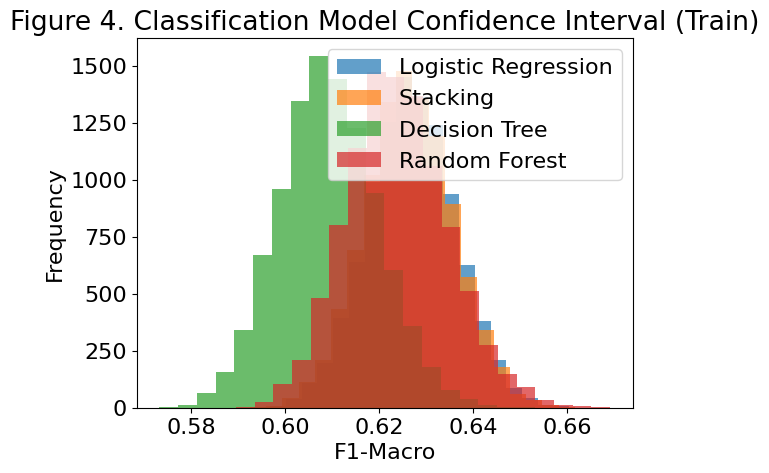

Logistic Regression Confidence Interval: (0.6095556422998178, 0.6459585674368298)
Stacking Confidence Interval: (0.6090025506611884, 0.6458451857473967)
Decision Tree Confidence Interval: (0.5909270368413196, 0.6319521493603147)
Random Forest Confidence Interval: (0.6063244988183836, 0.6498371524975902)


In [134]:
plt.hist(res_logr.bootstrap_distribution, bins=20, alpha=.7)
plt.hist(res_stacking_clf.bootstrap_distribution, bins=20, alpha=.7)
plt.hist(res_dt_clf.bootstrap_distribution, bins=20, alpha=.7)
plt.hist(res_rf_clf.bootstrap_distribution, bins=20, alpha=.7)
plt.legend(["Logistic Regression", "Stacking", "Decision Tree", "Random Forest"])
plt.ylabel("Frequency")
plt.xlabel("F1-Macro")
plt.title("Figure 4. Classification Model Confidence Interval (Train)")
plt.show()

print(f"Logistic Regression Confidence Interval: {float(res_logr.confidence_interval.low), float(res_logr.confidence_interval.high)}")
print(f"Stacking Confidence Interval: {float(res_stacking_clf.confidence_interval.low), float(res_stacking_clf.confidence_interval.high)}")
print(f"Decision Tree Confidence Interval: {float(res_dt_clf.confidence_interval.low), float(res_dt_clf.confidence_interval.high)}")
print(f"Random Forest Confidence Interval: {float(res_rf_clf.confidence_interval.low), float(res_rf_clf.confidence_interval.high)}")

### Feature selection and feature importance
Each model is refit using only the 5 most informative features. Permutation importance then shows how much logistic regression's F1-macro drops when each feature is shuffled.

In [ ]:
logr_fs_pipeline = Pipeline([
    ("process", preprocess),
    ("select", SelectKBest(mutual_info_classif, k=5)),
    ("clf", LogisticRegression(class_weight="balanced"))
])

In [89]:
logr_fs_pipeline.fit(X_train, y_train_clf)

y_pred = logr_fs_pipeline.predict(X_test)

print("F1 Macro: ", f1_score(y_test_clf, y_pred, average="macro"))
print("Classification Report:\n", classification_report(y_test_clf, y_pred))
print("Confusion Matrix\n", confusion_matrix(y_test_clf, y_pred))

F1 Macro:  0.6175091259542449
Classification Report:
               precision    recall  f1-score   support

           0       0.93      0.54      0.68     53483
           1       0.40      0.88      0.55     18901

    accuracy                           0.63     72384
   macro avg       0.66      0.71      0.62     72384
weighted avg       0.79      0.63      0.65     72384

Confusion Matrix
 [[28915 24568]
 [ 2315 16586]]


In [90]:
dt_clf_fs_pipeline = Pipeline([
    ("process", preprocess),
    ("select", SelectKBest(mutual_info_classif, k=5)),
    ("clf", DecisionTreeClassifier(random_state=23364203, 
                                  max_depth=best_dt_params_clf["clf__max_depth"],
                                    min_samples_leaf=best_dt_params_clf["clf__min_samples_leaf"], 
                                    class_weight="balanced"))
])

In [91]:
dt_clf_fs_pipeline.fit(X_train, y_train_clf)

y_pred = dt_clf_fs_pipeline.predict(X_test)

print("F1 Macro: ", f1_score(y_test_clf, y_pred, average="macro"))
print("Classification Report:\n", classification_report(y_test_clf, y_pred))
print("Confusion Matrix\n", confusion_matrix(y_test_clf, y_pred))

F1 Macro:  0.5916349352358451
Classification Report:
               precision    recall  f1-score   support

           0       0.94      0.49      0.64     53483
           1       0.39      0.91      0.54     18901

    accuracy                           0.60     72384
   macro avg       0.66      0.70      0.59     72384
weighted avg       0.80      0.60      0.62     72384

Confusion Matrix
 [[25982 27501]
 [ 1630 17271]]


In [92]:
knn_fs_pipeline = Pipeline([
    ("process", preprocess),
    ("select", SelectKBest(mutual_info_classif, k=5)),
    ("clf", KNeighborsClassifier(n_jobs=-1))
])

In [93]:
knn_fs_pipeline.fit(X_train, y_train_clf)

y_pred = knn_fs_pipeline.predict(X_test)

print("F1 Macro: ", f1_score(y_test_clf, y_pred, average="macro"))
print("Classification Report:\n", classification_report(y_test_clf, y_pred))
print("Confusion Matrix\n", confusion_matrix(y_test_clf, y_pred))

F1 Macro:  0.6101926371116322
Classification Report:
               precision    recall  f1-score   support

           0       0.79      0.81      0.80     53483
           1       0.43      0.40      0.42     18901

    accuracy                           0.71     72384
   macro avg       0.61      0.61      0.61     72384
weighted avg       0.70      0.71      0.70     72384

Confusion Matrix
 [[43503  9980]
 [11296  7605]]


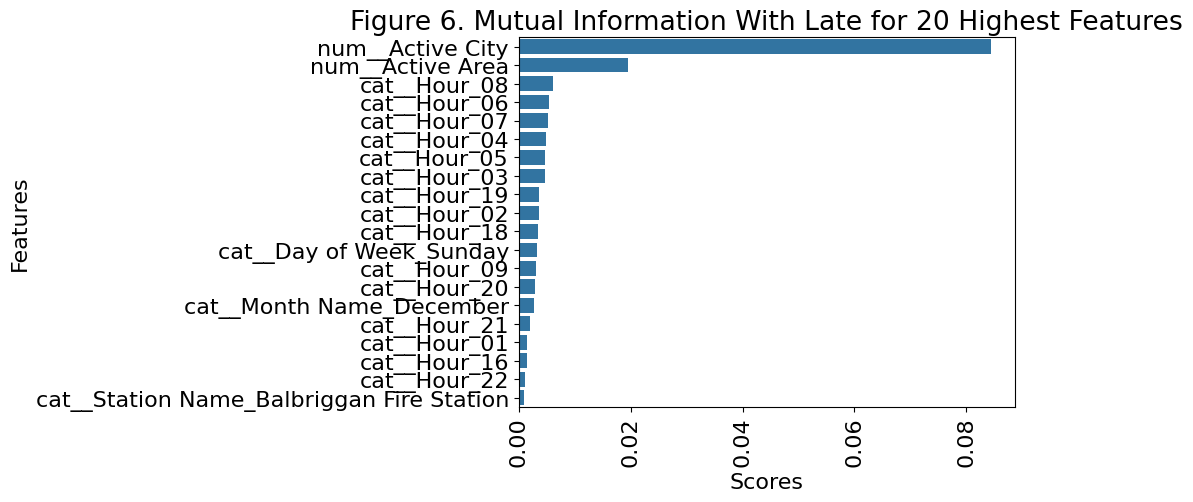

In [141]:
selector = dt_clf_fs_pipeline.named_steps["select"]
feature_names = dt_clf_fs_pipeline.named_steps["process"].get_feature_names_out()

feature_importance = pandas.DataFrame(selector.scores_, index=feature_names, columns=["Score"]).sort_values("Score", ascending=False)[:20]

sns.barplot(y=feature_importance.index, x=feature_importance["Score"])
plt.tick_params("x", rotation=90)
plt.ylabel("Features")
plt.xlabel("Scores")
plt.title("Figure 6. Mutual Information With Late for 20 Highest Features")
plt.show()

In [104]:
result_logr = permutation_importance(logr_pipeline, X_test, y_test_clf,
                                scoring="f1_macro",
                                n_repeats=5, random_state=23364203, n_jobs=-1)
perm_logr = pandas.Series(result_logr.importances_mean, index=X_test.columns).sort_values(ascending=False)



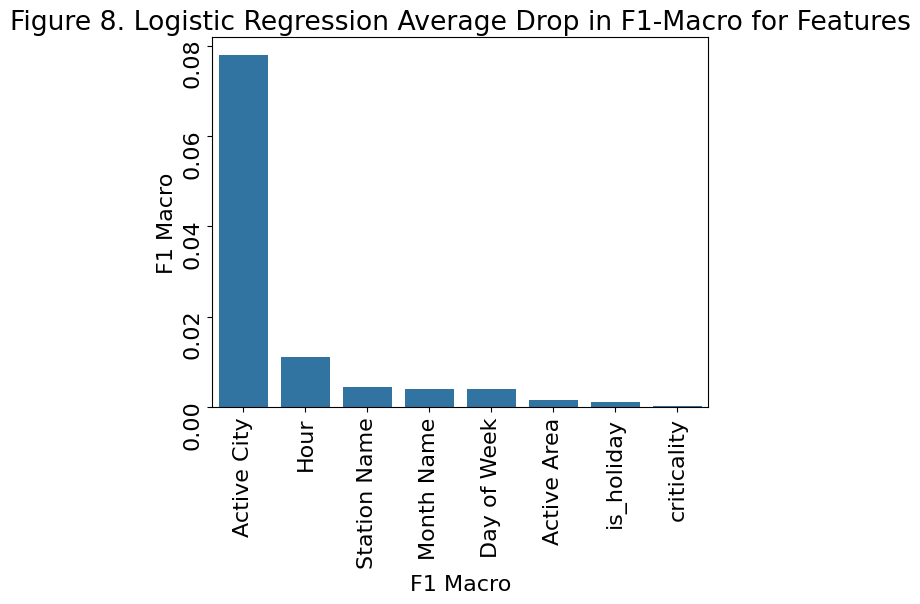

In [144]:
sns.barplot(perm_logr)
plt.ylabel("F1 Macro")
plt.xlabel("F1 Macro")
plt.tick_params(rotation=90)
plt.title("Figure 8. Logistic Regression Average Drop in F1-Macro for Features")
plt.show()